### 1. Importação de Bíbliotecas

In [2]:
import simpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Denifição de semente fixa, para que a simulação seja reprodutível em outras execuções.
np.random.seed(42)

### 2. Modelagem e Processamento Matemático

In [3]:
class SistemaBicicletas:
    def __init__(self, env, cap_origem=20, init_origem=15, cap_destino=20, init_destino=5):
        self.env = env
        self.estacao_origem = simpy.Container(env, capacity=cap_origem, init=init_origem)
        self.estacao_destino = simpy.Container(env, capacity=cap_destino, init=init_destino)
        
        # Novas variáveis para métricas obrigatórias
        self.registro_historico = []
        self.tempos_no_sistema = [] # Guarda o tempo total (Fila Origem + Viagem + Fila Destino)
        self.usuarios_ativos = 0    # Contador de pessoas na rua ou em filas
        self.desistencias_origem = 0
        self.desistencias_destino = 0
        
        env.process(self.monitorar_estacoes())

    def monitorar_estacoes(self):
        while True:
            # Fotografia do sistema a cada minuto
            self.registro_historico.append({
                'Minuto': self.env.now,
                'Bikes_Origem': self.estacao_origem.level,
                'Bikes_Destino': self.estacao_destino.level,
                'Vagas_Destino': self.estacao_destino.capacity - self.estacao_destino.level,
                'Usuarios_Ativos': self.usuarios_ativos
            })
            yield self.env.timeout(1)

def usuario_viagem(env, nome, sistema):
    # Marca o momento exato em que o usuário chega ao sistema
    tempo_chegada = env.now
    sistema.usuarios_ativos += 1
    
    # Tentativa de Retirada (Origem)
    req_bike = sistema.estacao_origem.get(1)
    resultado_retirada = yield req_bike | env.timeout(5)
    
    if req_bike not in resultado_retirada:
        sistema.desistencias_origem += 1
        sistema.usuarios_ativos -= 1 # Saiu do sistema por desistência
        return 
        
    # Tempo de Serviço (Duração da Viagem - 60 min média conforme pesquisa)
    tempo_viagem = np.random.exponential(scale=60) 
    yield env.timeout(tempo_viagem)
    
    # Tentativa de Devolução (Destino)
    req_vaga = sistema.estacao_destino.put(1)
    resultado_devolucao = yield req_vaga | env.timeout(10)
    
    if req_vaga not in resultado_devolucao:
        sistema.desistencias_destino += 1
        sistema.usuarios_ativos -= 1
        return
        
    # Sucesso: Calcula o tempo total no sistema e registra
    tempo_total = env.now - tempo_chegada
    sistema.tempos_no_sistema.append(tempo_total)
    sistema.usuarios_ativos -= 1 # Concluiu e saiu do sistema

def gerador_usuarios(env, sistema, taxa_chegada):
    i = 0
    while True:
        intervalo_chegada = np.random.exponential(scale=taxa_chegada)
        yield env.timeout(intervalo_chegada)
        i += 1
        env.process(usuario_viagem(env, f'User_{i}', sistema))

# Execução da Simulação
env = simpy.Environment()
sistema_base = SistemaBicicletas(env)
env.process(gerador_usuarios(env, sistema_base, taxa_chegada=3))
env.run(until=720) # Simula 12 horas

df_resultados = pd.DataFrame(sistema_base.registro_historico)

### 3. Visualização dos Dados & Gráficos

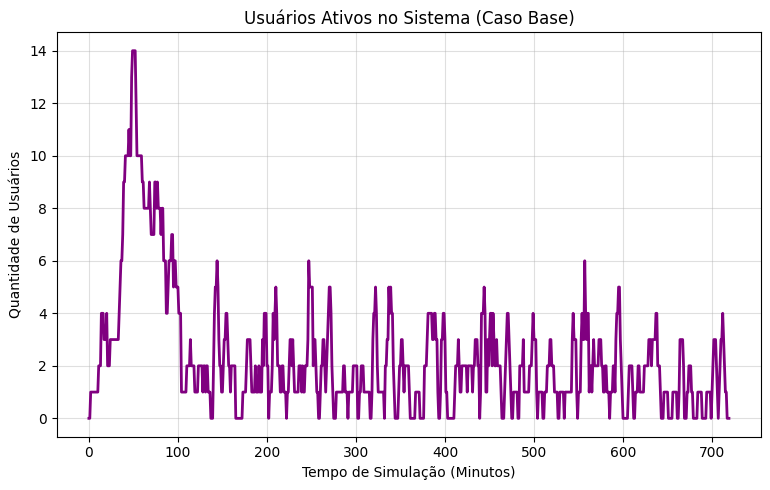

Tempo Médio no Sistema: 37.43 minutos
Tempo Máximo no Sistema (Outlier): 107.19 minutos


In [6]:
plt.figure(figsize=(15, 5))

# Gráfico 1: Quantidade de Usuários no Sistema ao longo do tempo
plt.subplot(1, 2, 1)
plt.plot(df_resultados['Minuto'], df_resultados['Usuarios_Ativos'], color='purple', linewidth=2)
plt.title('Usuários Ativos no Sistema (Caso Base)')
plt.xlabel('Tempo de Simulação (Minutos)')
plt.ylabel('Quantidade de Usuários')
plt.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

# Impressão das Estatísticas de Tempo
if len(sistema_base.tempos_no_sistema) > 0:
    tempo_medio = np.mean(sistema_base.tempos_no_sistema)
    tempo_max = np.max(sistema_base.tempos_no_sistema)
    print(f"Tempo Médio no Sistema: {tempo_medio:.2f} minutos")
    print(f"Tempo Máximo no Sistema (Outlier): {tempo_max:.2f} minutos")

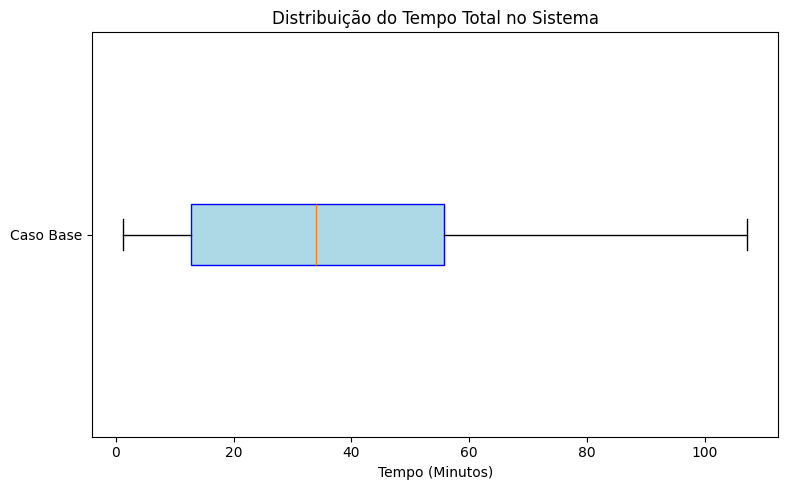

Tempo Médio no Sistema: 37.43 minutos
Tempo Máximo no Sistema (Outlier): 107.19 minutos


In [5]:
plt.figure(figsize=(15, 5))

# Gráfico 2: Tempo no Sistema (Boxplot para ver a distribuição e outliers)
plt.subplot(1, 2, 2)
# Verifica se houve viagens concluídas para evitar erro no gráfico
if len(sistema_base.tempos_no_sistema) > 0:
    plt.boxplot(sistema_base.tempos_no_sistema, vert=False, patch_artist=True, 
                boxprops=dict(facecolor='lightblue', color='blue'))
    plt.title('Distribuição do Tempo Total no Sistema')
    plt.xlabel('Tempo (Minutos)')
    plt.yticks([1], ['Caso Base'])
else:
    plt.text(0.5, 0.5, 'Nenhuma viagem concluída', ha='center', va='center')
    
plt.tight_layout()
plt.show()

# Impressão das Estatísticas de Tempo
if len(sistema_base.tempos_no_sistema) > 0:
    tempo_medio = np.mean(sistema_base.tempos_no_sistema)
    tempo_max = np.max(sistema_base.tempos_no_sistema)
    print(f"Tempo Médio no Sistema: {tempo_medio:.2f} minutos")
    print(f"Tempo Máximo no Sistema (Outlier): {tempo_max:.2f} minutos")